
# 04 — YOLOv8 Tumor Detection

## 4.1 — Detection Dataset Preparation and Audit

### Objective

Prepare the existing brain MRI dataset for YOLOv8 tumor detection and localization.

### Dataset

The classification preprocessing pipeline previously produced 3,913 unique images distributed into:

- Training: 2,739 images
- Validation: 587 images
- Testing: 587 images

We will reuse these split assignments to maintain dataset consistency and avoid exact-duplicate leakage between partitions.

### Detection Classes

The detection task includes three tumor classes:

| Detection ID | Class | Original ID |
|---|---|---|
| 0 | Glioma | 0 |
| 1 | Meningioma | 1 |
| 2 | Pituitary | 3 |

Images belonging to "No Tumor" will be treated as negative samples without tumor bounding boxes.

### Annotation Audit

For each image, verify:

1. The source image exists.
2. Its corresponding annotation file exists.
3. Each annotation follows the YOLO format.
4. Coordinates are valid and normalized.
5. Tumor class IDs are consistent with the expected categories.
6. Empty or suspicious annotations are identified.

Images requiring further review will be documented rather than silently corrected.

### Expected Outcome

Identify the number of images suitable for detection preprocessing and the number requiring annotation review.


In [2]:

from pathlib import Path
import pandas as pd
import numpy as np

# Project root
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Dataset paths
RAW_DIR = PROJECT_ROOT / "data/raw/brain_mri"
PROCESSED_DIR = PROJECT_ROOT / "data/processed"
MANIFEST_PATH = PROCESSED_DIR / "split_manifest.csv"

DETECTION_DIR = PROCESSED_DIR / "detection"

# Original dataset class mapping
ORIGINAL_CLASSES = {
    0: "Glioma",
    1: "Meningioma",
    2: "No Tumor",
    3: "Pituitary",
}

# YOLOv8 detection mapping
DETECTION_CLASSES = {
    0: "Glioma",
    1: "Meningioma",
    2: "Pituitary",
}

# Original class ID -> Detection class ID
CLASS_REMAP = {
    0: 0,
    1: 1,
    3: 2,
}

# Load the existing split manifest
manifest = pd.read_csv(MANIFEST_PATH)

assert manifest["hash"].is_unique, (
    "Duplicate image hashes in the manifest"
)

print("Total unique images:", len(manifest))
print("\nDataset splits:")
print(manifest["split"].value_counts())

print("\nClass distribution:")
print(
    pd.crosstab(
        manifest["split"],
        manifest["class_name"]
    )
)


Total unique images: 3913

Dataset splits:
split
train    2739
val       587
test      587
Name: count, dtype: int64

Class distribution:
class_name  Glioma  Meningioma  No Tumor  Pituitary
split                                              
test           179         164        90        154
train          833         766       421        719
val            178         165        90        154


In [3]:

import math

EXPECTED_IDS = {
    "Glioma": 0,
    "Meningioma": 1,
    "No Tumor": 2,
    "Pituitary": 3,
}

def inspect_annotation(row):
    image_path = PROJECT_ROOT / row["source_image"]

    label_path = (
        image_path.parent.parent
        / "labels"
        / f"{image_path.stem}.txt"
    )

    if not image_path.is_file():
        return "missing_image", 0, "Source image missing"

    if not label_path.is_file():
        return "missing_label", 0, "Annotation missing"

    try:
        lines = [
            line.strip()
            for line in label_path.read_text(
                encoding="utf-8-sig"
            ).splitlines()
            if line.strip()
        ]
    except Exception as exc:
        return "review", 0, f"Read error: {exc}"

    class_ids = []

    for line in lines:
        parts = line.split()

        if len(parts) != 5:
            return "review", len(lines), "Invalid YOLO format"

        try:
            class_id = int(parts[0])
            x, y, w, h = map(float, parts[1:])
        except ValueError:
            return "review", len(lines), "Invalid numeric values"

        if class_id not in ORIGINAL_CLASSES:
            return "review", len(lines), "Unknown class ID"

        if not all(math.isfinite(v) for v in (x, y, w, h)):
            return "review", len(lines), "Non-finite coordinates"

        if not (
            0 <= x <= 1
            and 0 <= y <= 1
            and 0 < w <= 1
            and 0 < h <= 1
        ):
            return "review", len(lines), "Invalid coordinates"

        tolerance = 1e-5

        if (
            x - w / 2 < -tolerance
            or x + w / 2 > 1 + tolerance
            or y - h / 2 < -tolerance
            or y + h / 2 > 1 + tolerance
        ):
            return "review", len(lines), "Box outside image"

        class_ids.append(class_id)

    class_name = row["class_name"]
    expected_id = EXPECTED_IDS[class_name]

    # Negative examples
    if class_name == "No Tumor":
        if all(cid == 2 for cid in class_ids):
            return "valid_negative", len(lines), "Background sample"

        return "review", len(lines), "Tumor ID in No Tumor folder"

    # Tumor-positive images
    if not class_ids:
        return "review", 0, "Empty tumor annotation"

    if any(cid != expected_id for cid in class_ids):
        return "review", len(lines), "Class-folder mismatch"

    return "valid_tumor", len(lines), "OK"


# Audit the representative images from the manifest
records = []

for _, row in manifest.iterrows():
    status, box_count, reason = inspect_annotation(row)

    records.append({
        "hash": row["hash"],
        "split": row["split"],
        "class_name": row["class_name"],
        "source_image": row["source_image"],
        "status": status,
        "box_count": box_count,
        "reason": reason,
    })

audit_df = pd.DataFrame(records)

# Summary
print("===== ANNOTATION AUDIT =====")
print("\nStatus distribution:")
print(audit_df["status"].value_counts())

print("\nStatus by split:")
print(pd.crosstab(
    audit_df["split"],
    audit_df["status"]
))

print("\nIssues requiring review:")
issues = audit_df[
    ~audit_df["status"].isin(
        ["valid_tumor", "valid_negative"]
    )
]

print(issues["reason"].value_counts())

print("\nExample issues:")
display(issues.head(10))

# Save audit report
audit_path = PROCESSED_DIR / "detection_annotation_audit.csv"

audit_df.to_csv(audit_path, index=False)

print("\nAudit report saved:", audit_path)


===== ANNOTATION AUDIT =====

Status distribution:
status
valid_tumor       3089
valid_negative     599
review             223
missing_label        2
Name: count, dtype: int64

Status by split:
status  missing_label  review  valid_negative  valid_tumor
split                                                     
test                0      24              90          473
train               1     164             420         2154
val                 1      35              89          462

Issues requiring review:
reason
Class-folder mismatch     222
Annotation missing          2
Empty tumor annotation      1
Name: count, dtype: int64

Example issues:


,hash,split,class_name,source_image,status,box_count,reason
1,901a6245ed8379ccea37a3a0ebd5c93d95b0555d790ed2...,train,Meningioma,data/raw/brain_mri/Train/Meningioma/images/Tr-...,review,2,Class-folder mismatch
13,acb3b1d0521046e97e583bd2283c52bbcbd8e63e7ed51c...,train,Glioma,data/raw/brain_mri/Train/Glioma/images/gg (306...,review,2,Class-folder mismatch
16,3a5282b3f1157d6f2ebb7b4a1d1f864bd260432040f5f8...,train,Glioma,data/raw/brain_mri/Train/Glioma/images/Tr-gl_0...,review,2,Class-folder mismatch
26,1c625422287b2054502134a3a6a1241ddfb030bed8addd...,train,Meningioma,data/raw/brain_mri/Train/Meningioma/images/Tr-...,review,2,Class-folder mismatch
50,7dc2255941d23f504ec38582ebd59f1696246859e97820...,train,Glioma,data/raw/brain_mri/Train/Glioma/images/gg (781...,review,3,Class-folder mismatch
73,5efa81291c0219d42b27d3998a46985dc4ad68e5f233f9...,train,Meningioma,data/raw/brain_mri/Train/Meningioma/images/Tr-...,review,2,Class-folder mismatch
88,f0321a6700ed7a9e6595a2d235465a312f4de5bbac07b2...,train,Meningioma,data/raw/brain_mri/Train/Meningioma/images/Tr-...,review,2,Class-folder mismatch
121,87cf5e4f7dcce6d49e96ce6e85cda414c9157471e25d36...,train,Glioma,data/raw/brain_mri/Train/Glioma/images/gg (291...,review,2,Class-folder mismatch
175,67f00a255eee7527742f68f6f76e8b4ba70de9370acec5...,train,Glioma,data/raw/brain_mri/Train/Glioma/images/Tr-gl_0...,review,2,Class-folder mismatch
183,4cfe02ccbdb9be081c98ba776db8f2f9662ce909c270cb...,train,Glioma,data/raw/brain_mri/Val/Glioma/images/gg (140).jpg,review,2,Class-folder mismatch



Audit report saved: /home/houssam/Desktop/Briefs/Brief 5/data/processed/detection_annotation_audit.csv



### 4.1 — Detection Annotation Audit: Findings

#### Objective

Verify the availability, structure, and class consistency of YOLO annotations associated with the 3,913 unique MRI images.

#### Dataset Distribution

| Split | Images |
|---|---:|
| Train | 2,739 |
| Validation | 587 |
| Test | 587 |
| Total | 3,913 |

#### Annotation Audit Results

| Status | Count |
|---|---:|
| Valid Tumor Annotations | 3,089 |
| Valid Negative Samples | 599 |
| Class-Folder Mismatches | 222 |
| Missing Annotation Files | 2 |
| Empty Tumor Annotations | 1 |

A total of 3,688 images (94.25%) passed the structural and class-consistency checks.

The remaining 225 images (5.75%) require additional review.

#### Results by Split

| Split | Accepted | Unresolved |
|---|---:|---:|
| Train | 2,574 | 165 |
| Validation | 551 | 36 |
| Test | 563 | 24 |

#### Analysis

**1. Annotation structure**

No invalid coordinate formats or out-of-bound boxes were reported for the inspected representative annotations.

This indicates that the main detected issue is class consistency rather than coordinate formatting.

**2. Class mismatches**

There are 222 images containing annotation class IDs that do not match their parent folders.

These cases require further inspection to distinguish potentially usable tumor annotations from mislabeled objects.

**3. Negative samples**

There are 599 structurally accepted No Tumor images.

These are candidates for background samples in YOLOv8, provided their image-level labels are reliable.

**4. Missing and empty annotations**

Two images have missing annotation files, and one tumor image has an empty annotation.

These cases require a documented decision before inclusion in the detection dataset.

**5. Dataset limitations**

Exact image duplicates were removed during classification preprocessing.

However, some duplicates originally contained inconsistent annotations, and near-duplicate or patient-level leakage has not been fully excluded.

#### Conclusion

Most selected MRI images passed the initial annotation audit.

Before generating the final YOLOv8 dataset, the class-folder mismatches must be investigated and the source class-ID mapping verified.

The original dataset and split manifest will remain unchanged.



## 4.2 — Investigation of Annotation Class Conflicts

### Objective

Analyze the 222 class-folder mismatches identified during the annotation audit.

### Questions

1. Does the annotation include the expected tumor class?
2. Which unexpected class IDs appear?
3. Do the conflicts involve No Tumor annotations or other tumor classes?
4. Are conflicting boxes positioned over actual tumors or other anatomical regions?
5. Can a reliable annotation be recovered without inventing labels?

### Methodology

Group mismatched images by their annotation class combinations and visualize representative cases with their bounding boxes.

No annotations will be modified at this stage.


In [4]:

from collections import Counter
from pathlib import Path
import pandas as pd

# Only images with class-folder mismatches
mismatches = audit_df[
    audit_df["reason"] == "Class-folder mismatch"
].copy()

def read_annotation_ids(source_image):
    image_path = PROJECT_ROOT / source_image

    label_path = (
        image_path.parent.parent
        / "labels"
        / f"{image_path.stem}.txt"
    )

    lines = label_path.read_text(
        encoding="utf-8-sig"
    ).splitlines()

    return [
        int(line.split()[0])
        for line in lines
        if line.strip()
    ]


def classify_mismatch(row):
    ids = read_annotation_ids(row["source_image"])
    expected = EXPECTED_IDS[row["class_name"]]

    has_expected = expected in ids

    has_other_tumor = any(
        i in {0, 1, 3} and i != expected
        for i in ids
    )

    has_no_tumor = 2 in ids

    if has_expected:
        if has_other_tumor:
            pattern = "Expected + other tumor"
        elif has_no_tumor:
            pattern = "Expected + No Tumor"
        else:
            pattern = "Other"
    else:
        if has_other_tumor:
            pattern = "No expected tumor; other tumor"
        elif has_no_tumor:
            pattern = "Only No Tumor"
        else:
            pattern = "Other"

    return pd.Series({
        "annotation_ids": ids,
        "expected_id": expected,
        "has_expected": has_expected,
        "pattern": pattern,
    })


details = mismatches.join(
    mismatches.apply(classify_mismatch, axis=1)
)

print("===== MISMATCH ANALYSIS =====")
print("Total mismatches:", len(details))

print("\nMismatch patterns:")
print(details["pattern"].value_counts())

print("\nPatterns by image class:")
print(pd.crosstab(
    details["class_name"],
    details["pattern"]
))

print("\nImages containing expected class:")
print(details["has_expected"].value_counts())

unexpected = Counter()

for _, row in details.iterrows():
    for class_id in row["annotation_ids"]:
        if class_id != row["expected_id"]:
            unexpected[class_id] += 1

print("\nUnexpected annotation ID frequencies:")
print(dict(sorted(unexpected.items())))

print("\nRepresentative cases:")
display(
    details[
        ["class_name", "annotation_ids",
         "expected_id", "pattern", "source_image"]
    ].head(15)
)


===== MISMATCH ANALYSIS =====
Total mismatches: 222

Mismatch patterns:
pattern
Expected + other tumor            209
No expected tumor; other tumor     13
Name: count, dtype: int64

Patterns by image class:
pattern     Expected + other tumor  No expected tumor; other tumor
class_name                                                        
Glioma                         145                               3
Meningioma                      64                               9
Pituitary                        0                               1

Images containing expected class:
has_expected
True     209
False     13
Name: count, dtype: int64

Unexpected annotation ID frequencies:
{0: 2, 1: 4, 3: 219}

Representative cases:


,class_name,annotation_ids,expected_id,pattern,source_image
1,Meningioma,"[1, 3]",1,Expected + other tumor,data/raw/brain_mri/Train/Meningioma/images/Tr-...
13,Glioma,"[0, 3]",0,Expected + other tumor,data/raw/brain_mri/Train/Glioma/images/gg (306...
16,Glioma,"[3, 0]",0,Expected + other tumor,data/raw/brain_mri/Train/Glioma/images/Tr-gl_0...
26,Meningioma,"[1, 3]",1,Expected + other tumor,data/raw/brain_mri/Train/Meningioma/images/Tr-...
50,Glioma,"[0, 0, 3]",0,Expected + other tumor,data/raw/brain_mri/Train/Glioma/images/gg (781...
73,Meningioma,"[1, 3]",1,Expected + other tumor,data/raw/brain_mri/Train/Meningioma/images/Tr-...
88,Meningioma,"[1, 3]",1,Expected + other tumor,data/raw/brain_mri/Train/Meningioma/images/Tr-...
121,Glioma,"[0, 3]",0,Expected + other tumor,data/raw/brain_mri/Train/Glioma/images/gg (291...
175,Glioma,"[0, 3]",0,Expected + other tumor,data/raw/brain_mri/Train/Glioma/images/Tr-gl_0...
183,Glioma,"[0, 3]",0,Expected + other tumor,data/raw/brain_mri/Val/Glioma/images/gg (140).jpg


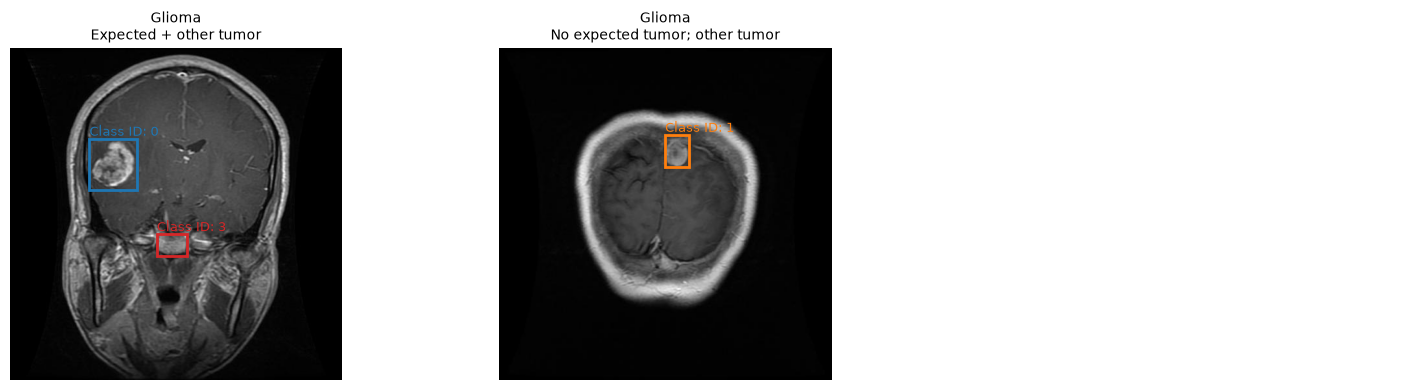

In [5]:

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
import math

# One representative example per mismatch pattern
examples = (
    details.sort_values("source_image")
    .groupby("pattern")
    .head(1)
    .head(6)
)

n = len(examples)

if n == 0:
    print("No mismatch examples found.")

else:
    cols = 3
    rows = math.ceil(n / cols)

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(15, 4 * rows)
    )

    axes = np.array(axes).reshape(-1)

    for ax, (_, record) in zip(axes, examples.iterrows()):

        image_path = PROJECT_ROOT / record["source_image"]
        label_path = (
            image_path.parent.parent
            / "labels"
            / f"{image_path.stem}.txt"
        )

        with Image.open(image_path) as image:
            image = image.convert("RGB")
            width, height = image.size
            ax.imshow(image)

        for line in label_path.read_text(
            encoding="utf-8-sig"
        ).splitlines():

            if not line.strip():
                continue

            values = line.split()

            class_id = int(values[0])
            xc, yc, bw, bh = map(float, values[1:])

            x = (xc - bw / 2) * width
            y = (yc - bh / 2) * height

            color = plt.cm.tab10(class_id % 10)

            rectangle = Rectangle(
                (x, y),
                bw * width,
                bh * height,
                fill=False,
                edgecolor=color,
                linewidth=2
            )

            ax.add_patch(rectangle)

            ax.text(
                x,
                max(0, y - 5),
                f"Class ID: {class_id}",
                color=color,
                fontsize=9
            )

        ax.set_title(
            f"{record['class_name']}\n{record['pattern']}",
            fontsize=10
        )

        ax.axis("off")

    for ax in axes[n:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()



### 4.2 — Annotation Class-Conflict Investigation: Findings

#### Objective

Investigate the 222 annotation mismatches to determine whether the expected tumor class is present and identify recurring class-label inconsistencies.

#### Results

| Pattern | Images |
|---|---:|
| Expected tumor class + other tumor class | 209 |
| Expected tumor class absent | 13 |
| Total | 222 |

#### Distribution by Image Class

| Class | Expected Present | Expected Absent |
|---|---:|---:|
| Glioma | 145 | 3 |
| Meningioma | 64 | 9 |
| Pituitary | 0 | 1 |

#### Unexpected Annotation IDs

- Class 0: 2 occurrences
- Class 1: 4 occurrences
- Class 3: 219 occurrences

#### Interpretation

**1. Dominant mismatch pattern**

209 of the 222 mismatched images contain their expected tumor class alongside one or more unexpected annotations.

Therefore, most conflicts do not involve a complete absence of the expected tumor class.

**2. Class-3 annotations**

Class ID 3 is responsible for most unexpected annotation occurrences.

Visual inspection of representative cases shows additional bounding boxes at locations that do not obviously correspond to the principal lesion.

However, image visualization alone is insufficient to establish whether these annotations are incorrect.

**3. Missing expected classes**

Thirteen images contain tumor annotations but no box corresponding to their parent folder class.

These cases cannot be corrected reliably using folder labels alone.

**4. Data quality decision**

The initial detection dataset will retain structurally valid and class-consistent annotations.

Unresolved annotations will be quarantined rather than automatically modified.

The original images and annotations will remain unchanged.

#### Initial Dataset Selection

- Valid tumor images: 3,089
- Valid negative images: 599
- Initial accepted dataset: 3,688
- Quarantined or excluded: 225

#### Conclusion

The dominant annotation problem is the presence of additional tumor-class labels, especially class ID 3.

A conservative detection dataset can be created using 3,688 accepted images while retaining the remaining cases for future annotation review.

This decision prioritizes annotation consistency over maximum dataset size.

The next step is to generate the YOLOv8 directory structure, remap tumor class IDs, and verify the resulting dataset.



## 4.3 — Preparing the YOLOv8 Dataset

### Objective

Generate a clean initial YOLOv8 detection dataset using the accepted annotations from the previous audit.

### Preparation Rules

1. Reuse the existing 70/15/15 split assignments.
2. Keep only images with accepted annotation status.
3. Preserve the original image content.
4. Retain validated tumor bounding boxes.
5. Remap original class IDs to the three detection classes.
6. Generate empty annotation files for accepted No Tumor images.
7. Exclude unresolved annotations and save an exclusion report.
8. Generate `data.yaml`.

### Class Mapping

| Original ID | YOLOv8 ID | Class |
|---|---|---|
| 0 | 0 | Glioma |
| 1 | 1 | Meningioma |
| 2 | Background | No Tumor |
| 3 | 2 | Pituitary |

### Expected Dataset Size

| Split | Images |
|---|---:|
| Train | 2,574 |
| Validation | 551 |
| Test | 563 |
| Total | 3,688 |

These totals are based on the annotation audit and will be verified after copying.

### You can go to src/detection/prepare_data.py for the script


### 4.3 — YOLOv8 Dataset Preparation: Findings

#### Objective

Generate a structured YOLOv8 detection dataset using the validated annotations and the existing deduplicated train, validation, and test splits.

#### Results

| Split | Images | Labels | Negative Samples |
|---|---:|---:|---:|
| Train | 2,574 | 2,574 | 420 |
| Validation | 551 | 551 | 89 |
| Test | 563 | 563 | 90 |
| Total | 3,688 | 3,688 | 599 |

#### Dataset Composition

- Accepted tumor images: 3,089
- Accepted negative images: 599
- Total accepted images: 3,688
- Excluded images requiring review: 225
- Dataset retention rate: 94.25%

#### Class Configuration

| Detection ID | Class |
|---|---|
| 0 | Glioma |
| 1 | Meningioma |
| 2 | Pituitary |

The original "No Tumor" category is represented by background images with empty annotation files.

#### Analysis

**1. Dataset organization**

Images and labels were organized into matching train, validation, and test directories.

The generated dataset preserved the existing split assignments from classification preprocessing.

**2. Annotation conversion**

Accepted tumor annotations were converted to the three-class YOLOv8 mapping.

Negative images received empty annotation files, without artificial bounding boxes.

**3. Dataset integrity**

All 3,688 copied images have corresponding annotation files.

The preparation script completed without reporting missing destinations or mismatched image-label counts.

**4. Excluded samples**

The 225 unresolved images were excluded from the initial training dataset and documented for future review.

**5. Remaining verification**

The preparation counts are correct, but bounding-box validity, remapped class IDs, and image-annotation alignment must still be checked independently.

#### Conclusion

The initial YOLOv8 dataset has been prepared successfully.

The next step is to validate the generated annotation files and visually inspect representative MRI images with their bounding boxes before model training.



## 4.4 — YOLOv8 Dataset Verification

### Objective

Verify that the generated YOLOv8 dataset is structurally correct before model training.

### Verification Checks

1. Confirm that every image has its corresponding annotation file.
2. Verify that all image files are readable.
3. Check that the detection class IDs are 0, 1, or 2.
4. Verify normalized bounding-box coordinates and image boundaries.
5. Confirm that negative samples have no bounding boxes.
6. Verify that positive samples contain the expected class.
7. Confirm that no exact image hashes are shared across data splits.

### Expected Outcome

All 3,688 images should pass the structural checks.

The dataset must contain 3,089 positive images and 599 background images.


In [9]:

from pathlib import Path
from collections import Counter
from PIL import Image
import pandas as pd
import math

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DETECTION_DIR = (
    PROJECT_ROOT / "data/processed/detection"
)

detection_manifest = pd.read_csv(
    DETECTION_DIR / "detection_manifest.csv"
)

EXPECTED_CLASSES = {
    "Glioma": 0,
    "Meningioma": 1,
    "Pituitary": 2,
}

errors = []
class_boxes = Counter()
seen_hashes = set()

print("===== YOLO DATASET VERIFICATION =====")

for split in ["train", "val", "test"]:
    image_dir = DETECTION_DIR / "images" / split
    label_dir = DETECTION_DIR / "labels" / split

    records = detection_manifest[
        detection_manifest["split"] == split
    ]

    image_files = [
        p for p in image_dir.iterdir()
        if p.suffix.lower() in {
            ".jpg", ".jpeg", ".png", ".bmp"
        }
    ]

    label_files = list(label_dir.glob("*.txt"))

    assert len(image_files) == len(records)
    assert len(label_files) == len(records)

    positives = 0
    negatives = 0
    box_count = 0

    for row in records.itertuples(index=False):
        image_name = Path(row.processed_image).name
        image_path = image_dir / image_name
        label_path = label_dir / (
            Path(image_name).stem + ".txt"
        )

        if not image_path.is_file():
            errors.append(f"Missing image: {image_path}")
            continue

        if not label_path.is_file():
            errors.append(f"Missing label: {label_path}")
            continue

        # Verify image readability
        try:
            with Image.open(image_path) as image:
                image.verify()
        except Exception as exc:
            errors.append(f"Invalid image: {exc}")
            continue

        # Detect exact-hash overlap
        image_hash = Path(image_name).stem

        if image_hash in seen_hashes:
            errors.append(f"Repeated hash: {image_hash}")

        seen_hashes.add(image_hash)

        lines = [
            line.strip()
            for line in label_path.read_text().splitlines()
            if line.strip()
        ]

        # Negative sample verification
        if row.class_name == "No Tumor":
            negatives += 1

            if lines:
                errors.append(
                    f"Negative image has boxes: {label_path}"
                )

            continue

        positives += 1
        expected_id = EXPECTED_CLASSES[row.class_name]

        if not lines:
            errors.append(
                f"Positive image has no boxes: {label_path}"
            )
            continue

        for line in lines:
            parts = line.split()

            if len(parts) != 5:
                errors.append(f"Invalid format: {label_path}")
                continue

            try:
                class_id = int(parts[0])
                x, y, w, h = map(float, parts[1:])
            except ValueError:
                errors.append(f"Invalid values: {label_path}")
                continue

            if class_id != expected_id:
                errors.append(
                    f"Unexpected class ID in {label_path}"
                )

            coords = [x, y, w, h]

            if not all(math.isfinite(v) for v in coords):
                errors.append(f"Non-finite box: {label_path}")
                continue

            tol = 1e-5

            valid = (
                0 <= x <= 1
                and 0 <= y <= 1
                and 0 < w <= 1
                and 0 < h <= 1
                and x - w/2 >= -tol
                and x + w/2 <= 1 + tol
                and y - h/2 >= -tol
                and y + h/2 <= 1 + tol
            )

            if not valid:
                errors.append(f"Invalid box: {label_path}")

            class_boxes[class_id] += 1
            box_count += 1

    print(f"\n{split.upper()}")
    print("Images:", len(image_files))
    print("Labels:", len(label_files))
    print("Tumor images:", positives)
    print("Negative images:", negatives)
    print("Bounding boxes:", box_count)

print("\n===== BOUNDING BOX DISTRIBUTION =====")

for class_id, class_name in enumerate(
    ["Glioma", "Meningioma", "Pituitary"]
):
    print(f"{class_name}: {class_boxes[class_id]}")

print("\nTotal validation errors:", len(errors))

if errors:
    for error in errors[:20]:
        print(error)

    raise AssertionError(
        f"Dataset verification failed: {len(errors)} errors"
    )

print("\nDataset verification passed.")


===== YOLO DATASET VERIFICATION =====

TRAIN
Images: 2574
Labels: 2574
Tumor images: 2154
Negative images: 420
Bounding boxes: 2343

VAL
Images: 551
Labels: 551
Tumor images: 462
Negative images: 89
Bounding boxes: 501

TEST
Images: 563
Labels: 563
Tumor images: 473
Negative images: 90
Bounding boxes: 507

===== BOUNDING BOX DISTRIBUTION =====
Glioma: 1211
Meningioma: 1045
Pituitary: 1095

Total validation errors: 0

Dataset verification passed.



## 4.5 — Bounding Box Visualization

### Objective

Visually inspect the prepared YOLOv8 annotations to verify that bounding boxes align with the expected tumor regions.

### Methodology

- Display two Glioma images.
- Display two Meningioma images.
- Display two Pituitary images.
- Display two No Tumor background images.
- Draw the converted YOLO bounding boxes on the original images.
- Display class names beside the bounding boxes.

### Evaluation

Verify whether the annotations are visually plausible and whether the negative images contain no labeled objects.

This visual audit does not replace expert medical annotation review.


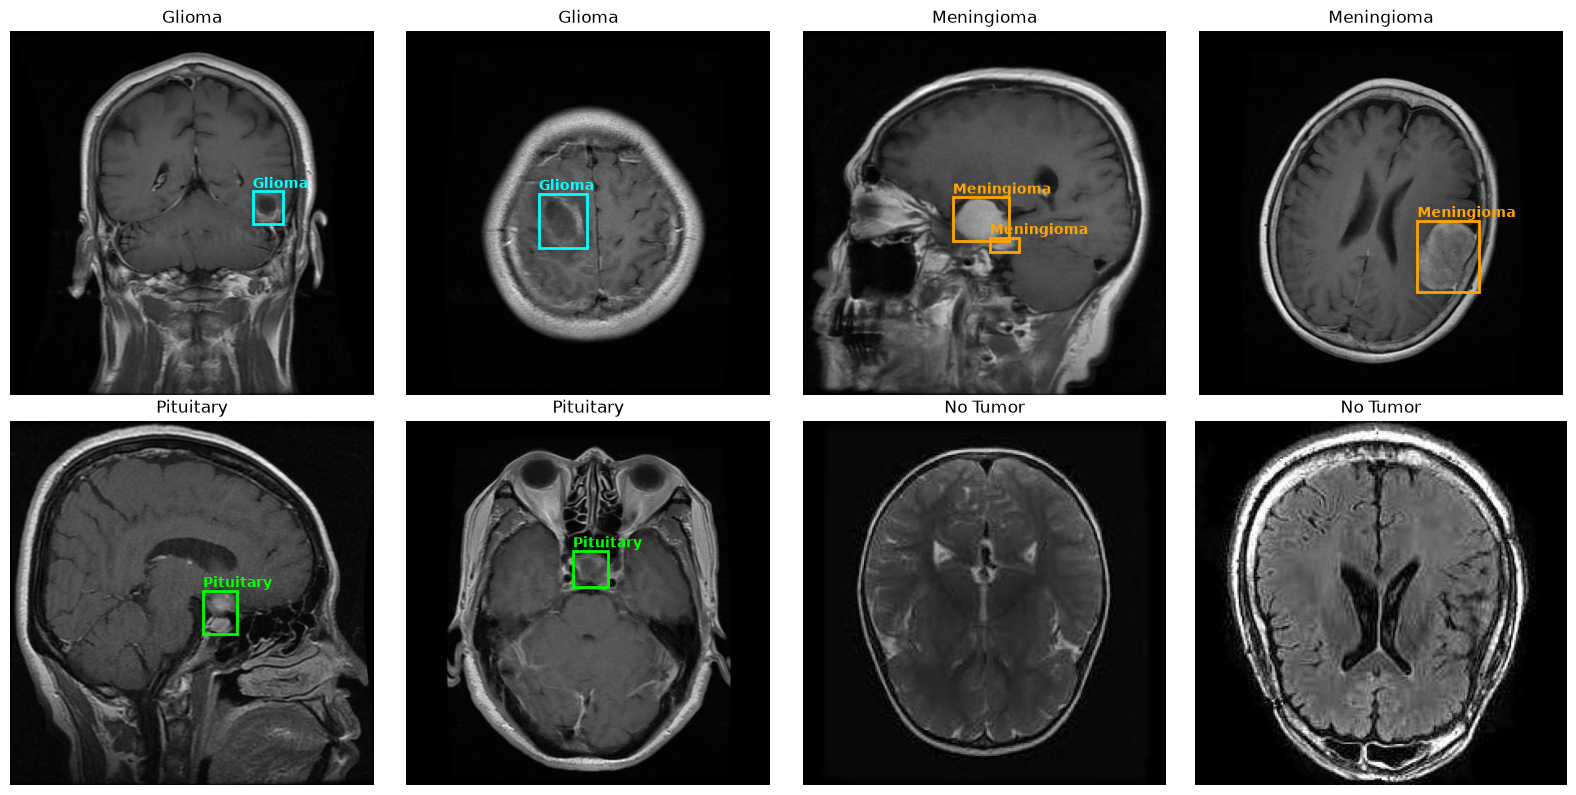

In [10]:

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
import numpy as np

CLASS_NAMES = {
    0: "Glioma",
    1: "Meningioma",
    2: "Pituitary",
}

COLORS = {
    0: "cyan",
    1: "orange",
    2: "lime",
}

# Select two reproducible training examples per class
samples = []

train_records = detection_manifest[
    detection_manifest["split"] == "train"
]

for class_name in [
    "Glioma",
    "Meningioma",
    "Pituitary",
    "No Tumor",
]:
    candidates = train_records[
        train_records["class_name"] == class_name
    ]

    selected = candidates.sample(
        n=min(2, len(candidates)),
        random_state=42,
    )

    samples.extend(
        selected.to_dict("records")
    )

# Create visualization
fig, axes = plt.subplots(
    2, 4,
    figsize=(16, 8),
)

axes = axes.flatten()

for ax, record in zip(axes, samples):
    image_name = Path(record["processed_image"]).name

    image_path = (
        DETECTION_DIR / "images" / "train" / image_name
    )

    label_path = (
        DETECTION_DIR / "labels" / "train"
        / f"{Path(image_name).stem}.txt"
    )

    with Image.open(image_path) as img:
        img = img.convert("RGB")
        width, height = img.size
        ax.imshow(img)

    lines = [
        line.strip()
        for line in label_path.read_text().splitlines()
        if line.strip()
    ]

    for line in lines:
        values = line.split()

        class_id = int(values[0])
        xc, yc, bw, bh = map(float, values[1:])

        # Convert YOLO normalized coordinates to pixels
        x_min = (xc - bw / 2) * width
        y_min = (yc - bh / 2) * height

        box_width = bw * width
        box_height = bh * height

        color = COLORS[class_id]

        rectangle = Rectangle(
            (x_min, y_min),
            box_width,
            box_height,
            fill=False,
            edgecolor=color,
            linewidth=2,
        )

        ax.add_patch(rectangle)

        ax.text(
            x_min,
            max(0, y_min - 5),
            CLASS_NAMES[class_id],
            color=color,
            fontsize=10,
            weight="bold",
        )

    ax.set_title(
        record["class_name"],
        fontsize=12,
    )

    ax.axis("off")

for ax in axes[len(samples):]:
    ax.axis("off")

plt.tight_layout()
plt.show()



### 4.4 — Final YOLOv8 Dataset Verification: Findings

#### Objective

Verify the generated YOLOv8 detection dataset and visually inspect the bounding-box annotations before training.

#### Structural Verification

| Split | Images | Labels | Positive Images | Negative Images | Boxes |
|---|---:|---:|---:|---:|---:|
| Train | 2,574 | 2,574 | 2,154 | 420 | 2,343 |
| Validation | 551 | 551 | 462 | 89 | 501 |
| Test | 563 | 563 | 473 | 90 | 507 |
| Total | 3,688 | 3,688 | 3,089 | 599 | 3,351 |

#### Annotation Distribution

- Glioma: 1,211 bounding boxes
- Meningioma: 1,045 bounding boxes
- Pituitary: 1,095 bounding boxes

#### Integrity Results

- Total structural validation errors: 0
- All expected images and annotation files were found.
- All verified images were readable.
- Bounding-box coordinates satisfied the required normalized YOLO format.
- Detection class IDs matched their expected classes.
- Negative samples contained no bounding boxes.
- No repeated image hashes were reported by the verification script.

#### Visual Inspection

Eight representative training images were displayed:

- Two Glioma images
- Two Meningioma images
- Two Pituitary images
- Two No Tumor images

The annotations generally aligned with the intended image regions.

One Meningioma example contained multiple nearby bounding boxes. These require an additional overlap check to identify possible redundant annotations.

#### Interpretation

The dataset passed all implemented structural integrity checks.

The total number of bounding boxes exceeds the number of positive images because some images contain multiple annotations.

Structural consistency does not guarantee clinical annotation accuracy.

#### Conclusion

The initial YOLOv8 dataset is structurally ready for baseline training, subject to a final lightweight check for redundant overlapping boxes.

The next phase is training a pretrained YOLOv8 detection model.


In [11]:

from itertools import combinations
from pathlib import Path

def box_to_xyxy(values):
    x, y, w, h = map(float, values)
    return (
        x - w / 2,
        y - h / 2,
        x + w / 2,
        y + h / 2,
    )

def calculate_iou(a, b):
    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])
    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])

    intersection = max(0, x2-x1) * max(0, y2-y1)

    area_a = (a[2]-a[0]) * (a[3]-a[1])
    area_b = (b[2]-b[0]) * (b[3]-b[1])

    union = area_a + area_b - intersection
    return intersection / union if union > 0 else 0

suspicious = []
multi_box_images = 0

for split in ["train", "val", "test"]:
    label_dir = DETECTION_DIR / "labels" / split

    for label_path in label_dir.glob("*.txt"):
        lines = [
            line.split()
            for line in label_path.read_text().splitlines()
            if line.strip()
        ]

        if len(lines) > 1:
            multi_box_images += 1

        for a, b in combinations(lines, 2):
            if a[0] != b[0]:
                continue

            iou = calculate_iou(
                box_to_xyxy(a[1:]),
                box_to_xyxy(b[1:]),
            )

            if iou >= 0.80:
                suspicious.append({
                    "split": split,
                    "image": label_path.stem,
                    "class_id": int(a[0]),
                    "iou": round(iou, 4),
                })

print("Images with multiple boxes:", multi_box_images)
print("Highly overlapping box pairs:", len(suspicious))

for item in suspicious[:10]:
    print(item)


Images with multiple boxes: 228
Highly overlapping box pairs: 0



# 05 — YOLOv8 Tumor Detection Training

## 5.1 — Baseline Experiment

### Objective

Train a pretrained YOLOv8 detector to localize and classify three brain tumor categories.

### Model Selection

YOLOv8n (Nano) is selected as the initial baseline because it is lightweight and suitable for experimenting on a laptop GPU.

### Dataset

- Training images: 2,574
- Validation images: 551
- Test images: 563
- Detection classes: 3

### Training Strategy

Use pretrained YOLOv8 weights and adapt the network to the MRI detection dataset.

Only training data will receive augmentation.

### Evaluation Metrics

- Precision
- Recall
- mAP@0.5
- mAP@0.5:0.95
- Class-specific performance

The validation dataset will be used during training. The test dataset will not be used for model selection.


In [ ]:

from pathlib import Path
from ultralytics import YOLO
import torch

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_YAML = (
    PROJECT_ROOT
    / "data/processed/detection/data.yaml"
)

RUNS_DIR = PROJECT_ROOT / "models/detection"

assert DATA_YAML.is_file()
assert torch.cuda.is_available(), "CUDA GPU unavailable"

# Pretrained YOLOv8 Nano detector
model = YOLO("yolov8n.pt")

# Train on the MRI dataset
results = model.train(
    data=str(DATA_YAML),
    epochs=60,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    patience=12,

    # Conservative augmentation
    degrees=5.0,
    translate=0.03,
    scale=0.10,
    fliplr=0.0,
    flipud=0.0,
    hsv_h=0.0,
    hsv_s=0.0,
    hsv_v=0.05,
    mosaic=0.0,
    mixup=0.0,

    # Reproducibility
    seed=42,
    deterministic=True,

    # Performance
    amp=True,
    cache=False,

    # Save experiment
    project=str(RUNS_DIR),
    name="yolov8n_baseline",
    exist_ok=False,
    plots=True,
    save=True,
)

print("Training completed")
print("Results directory:", model.trainer.save_dir)
